In [12]:
# --- IMPORTS & DATA LOADING ---

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual configurations
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")


Libraries imported successfully!


In [13]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

df_final = pd.read_parquet("../data/processed/pld_se_co_monthly.parquet")
display(df_final.head())
print(f"Loaded {len(df_final)} months")



,pld_se_co,load_seco_mwmed,ear_seco_mwmes,ena_seco_mwmed,thermal_gen_seco_mwmed
date,,,,,
2017-01-01,121.44,39881.955585,69836.612903,43990.903226,4221.813172
2017-02-01,128.43,40979.009545,80383.464286,49413.428571,4145.487351
2017-03-01,216.24,40491.735269,83858.096774,45626.032258,5496.185484
2017-04-01,371.47,37739.542232,84446.433333,39045.966667,6608.565278
2017-05-01,411.49,36876.019168,85763.161290,38930.387097,6202.169355


Loaded 105 months


# --- Q1: IS THE PLD DIFFERENT BETWEEN DRY AND WET PERIODS? ---

In [18]:
# 1. Define the hydrological period of each month (dry: May-Nov, wet: Dec-Apr)

def get_period(month):
    """
    Return the hydrological period of a given month number.
    """
    
    if month >= 5 and month <= 11:
        return "dry"
    else:
        return "wet"

df_q1 = df_final.copy()
df_q1["period"] = df_q1.index.month.map(get_period)

# 2. Descriptive statistics by period
print(df_q1.groupby("period")["pld_se_co"].describe())

        count        mean         std    min      25%      50%      75%  \
period                                                                    
dry      61.0  232.582295  173.254636  55.70  78.5200  210.020  325.460   
wet      44.0  144.157955   98.336568  39.68  64.3275  109.365  205.695   

           max  
period          
dry     583.88  
wet     443.66  


* The dry period has a higher and more volatile PLD: mean of R$ 232.6/MWh vs R$ 144.2/MWh in the wet period, and a median of R$ 210.0 vs R$ 109.4 (61 dry months vs 44 wet months).
* The dry period spread is much larger (std of 173.3 vs 98.3), and its mean is above its median, a sign of a right-skewed distribution driven by price spikes.
* The lower quartiles are similar (R$ 78.5 vs R$ 64.3), consistent with the regulatory price floor limiting how low the PLD can go in both periods.

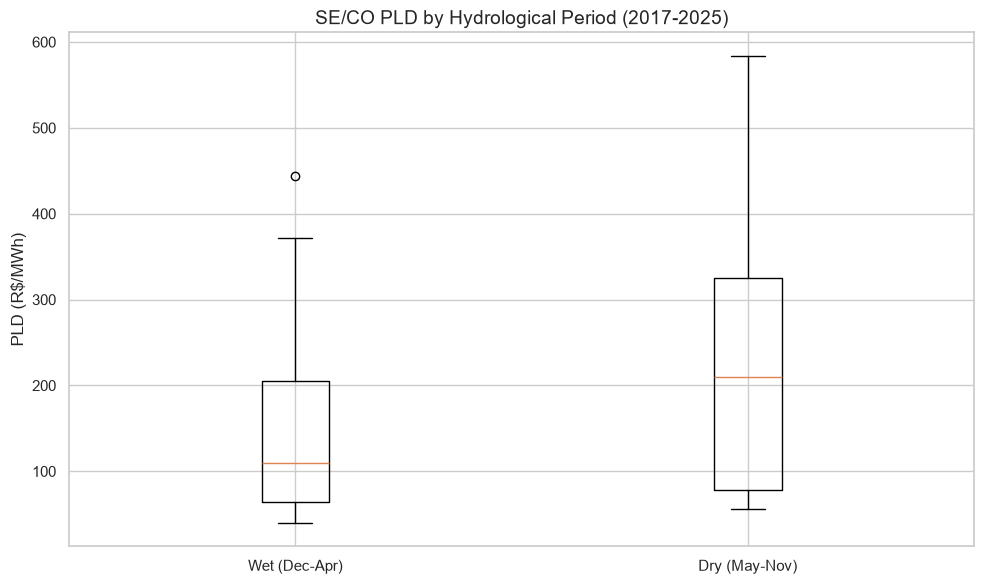

In [19]:
# 3. Boxplot
dry = df_q1.loc[df_q1["period"] == "dry", "pld_se_co"]
wet = df_q1.loc[df_q1["period"] == "wet", "pld_se_co"]

plt.figure(figsize=(10, 6))
plt.boxplot([wet, dry], tick_labels=["Wet (Dec-Apr)", "Dry (May-Nov)"])
plt.ylabel("PLD (R$/MWh)")
plt.title("SE/CO PLD by Hydrological Period (2017-2025)", fontsize=14)
plt.tight_layout()
plt.savefig("../outputs/boxplot_pld_dry_vs_wet.png", dpi=300)
plt.show()


* The dry period median (~R$ 210/MWh) is almost equal to the 75th percentile of the wet period (~R$ 206/MWh): a typical dry month is as expensive as a high wet month.
* The dry period has a much wider box and upper whisker (up to R$ 584/MWh), while the wet period is more concentrated, with a single outlier (~R$ 444/MWh).
* Both periods share a similar lower bound, so the difference is concentrated in the upper part of the distribution (price spikes), not in the cheapest months.

In [20]:
# 4. Hypothesis test (Mann-Whitney) + difference and bootstrap confidence interval
def compare_periods(dry_values, wet_values):
    """Run Mann-Whitney and print the difference in means with a 95% bootstrap CI."""
    stat, p_value = stats.mannwhitneyu(dry_values, wet_values, alternative="two-sided")

    mean_diff = dry_values.mean() - wet_values.mean()
    pct_diff = mean_diff / wet_values.mean() * 100

    # Bootstrap: resample each group with replacement 5000 times
    rng = np.random.default_rng(42)
    diffs = []
    for i in range(5000):
        sample_dry = rng.choice(dry_values, size=len(dry_values), replace=True)
        sample_wet = rng.choice(wet_values, size=len(wet_values), replace=True)
        diffs.append(sample_dry.mean() - sample_wet.mean())
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])

    print(f"Mann-Whitney p-value: {p_value:.4f}")
    print(f"Mean PLD dry: {dry_values.mean():.1f} | wet: {wet_values.mean():.1f} (R$/MWh)")
    print(f"Difference (dry - wet): {mean_diff:.1f} R$/MWh ({pct_diff:.1f}%)")
    print(f"95% bootstrap CI for the difference: [{ci_low:.1f}, {ci_high:.1f}]")

print("=== Full period (2017-2025) ===")
compare_periods(dry, wet)

# 5. Robustness: exclude 2022-2024 (PLD at the regulatory floor)
df_robust = df_q1[(df_q1.index.year < 2022) | (df_q1.index.year > 2024)]
dry_r = df_robust.loc[df_robust["period"] == "dry", "pld_se_co"]
wet_r = df_robust.loc[df_robust["period"] == "wet", "pld_se_co"]

print("\n=== Excluding 2022-2024 ===")
compare_periods(dry_r, wet_r)

=== Full period (2017-2025) ===
Mann-Whitney p-value: 0.0072
Mean PLD dry: 232.6 | wet: 144.2 (R$/MWh)
Difference (dry - wet): 88.4 R$/MWh (61.3%)
95% bootstrap CI for the difference: [35.7, 141.0]

=== Excluding 2022-2024 ===
Mann-Whitney p-value: 0.0031
Mean PLD dry: 300.6 | wet: 186.1 (R$/MWh)
Difference (dry - wet): 114.5 R$/MWh (61.5%)
95% bootstrap CI for the difference: [52.2, 177.4]


* The difference is statistically significant: the dry period PLD is R$ 88.4/MWh (61.3%) higher than the wet period (Mann-Whitney p = 0.007), and the 95% bootstrap CI [35.7, 141.0] does not include zero.
* Robustness: excluding 2022-2024 (PLD at the regulatory floor) the result holds and the gap widens to R$ 114.5/MWh (CI [52.2, 177.4], p = 0.003). The relative difference is nearly the same (61.5%), so the floor years dilute the absolute gap but do not create it.
* Caveat: consecutive months are autocorrelated, so the p-values are likely optimistic and the confidence intervals are wide. The 2021 water crisis falls in the dry period and may inflate part of the gap.